# Modelos de regresión - Viajes en taxi de Nueva York (enero 2015)

Se entrenaron y compararon modelos de regresión sobre el dataset limpio `yellow_tripdata_2015-01_clean.csv` para predecir la duración del viaje (`trip_duration_min`) a partir de la hora de partida y las coordenadas de partida y llegada.

### Importar datos

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyproj import Transformer
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

PATH = "../data/yellow_tripdata_2015-01_clean.csv"
CHUNK = 2_000_000
cols = {1: "tpep_pickup_datetime", 5: "pickup_longitude", 6: "pickup_latitude",
        9: "dropoff_longitude", 10: "dropoff_latitude", 19: "trip_duration_min"}

partes = []
for chunk in pd.read_csv(PATH, header=None, skiprows=1, usecols=list(cols), chunksize=CHUNK):
    chunk.columns = list(cols.values())
    pickup = pd.to_datetime(chunk.pop("tpep_pickup_datetime"), format="%Y-%m-%d %H:%M:%S")
    chunk.insert(0, "pickup_hour", pickup.dt.hour + pickup.dt.minute / 60)
    partes.append(chunk.astype(np.float32))
df = pd.concat(partes, ignore_index=True)
del partes

features = ["pickup_hour", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
X = df[features].to_numpy()
y = df["trip_duration_min"].to_numpy(np.float64)
del df

print(f"Filas: {len(X):,}")
print(f"Variables: {features}")

Filas: 12,402,772
Variables: ['pickup_hour', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']


### Pipeline

Se comparan tres modelos sobre las mismas variables de dominio:
- **Lineal**: regresión lineal sin regularización.
- **GB**: gradient boosting (`HistGradientBoostingRegressor`, 600 árboles, tasa de aprendizaje 0.05, hasta 127 hojas por árbol).
- **RF**: random forest (`RandomForestRegressor`, 100 árboles, profundidad máxima 20, √p variables por división, cada árbol entrenado con 500 000 viajes).

Las coordenadas se proyectan en km (Transversa de Mercator centrada en Midtown) y se rotan 29° según la grilla de calles de Manhattan. Las variables de dominio son:
- Armónicos `sin(2πkh/24)` y `cos(2πkh/24)` de la hora de partida, con k = 1, 2, 3.
- Coordenadas proyectadas de partida y llegada, y su distancia a Midtown.
- Distancia en línea recta y Manhattan (L1) entre partida y llegada, e indicador de viajes con menos de 0.1 mi en línea recta.
- Orientación del viaje respecto de la grilla, `cos 2θ` (1 a lo largo de las avenidas, -1 en sentido transversal).
- Interacciones de la distancia en línea recta con los armónicos de la hora y con la distancia de partida y llegada a Midtown.

In [14]:
PROYECCION = Transformer.from_crs("EPSG:4326", "+proj=tmerc +lat_0=40.754 +lon_0=-73.984 +ellps=WGS84 +units=km", always_xy=True)
ANGULO = np.deg2rad(29)

def proyectar(lon, lat):
    x, y = PROYECCION.transform(lon, lat)
    return x * np.sin(ANGULO) + y * np.cos(ANGULO), x * np.cos(ANGULO) - y * np.sin(ANGULO)

class Dominio(TransformerMixin, BaseEstimator):
    def __init__(self, armonicos=3):
        self.armonicos = armonicos

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.astype(np.float64)
        p = np.column_stack(proyectar(X[:, 1], X[:, 2]))
        q = np.column_stack(proyectar(X[:, 3], X[:, 4]))
        dx, dy = q[:, 0] - p[:, 0], q[:, 1] - p[:, 1]
        d = np.hypot(dx, dy) / 1.609
        rp, rq = np.hypot(*p.T), np.hypot(*q.T)
        ang = 2 * np.pi * X[:, :1] * np.arange(1, self.armonicos + 1) / 24
        hora = np.hstack([np.sin(ang), np.cos(ang)])
        return np.hstack([
            np.column_stack([d, (np.abs(dx) + np.abs(dy)) / 1.609, d < 0.1, np.cos(2 * np.arctan2(dy, dx)),
                             p, q, rp, rq, d * rp, d * rq]),
            hora, d[:, None] * hora,
        ])

    def get_feature_names_out(self, input_features=None):
        hora = [f"{f}({k}·2πh/24)" for f in ("sin", "cos") for k in range(1, self.armonicos + 1)]
        return np.array(["d", "d L1", "d < 0.1", "cos 2θ", "u partida", "v partida", "u llegada", "v llegada",
                         "r partida", "r llegada", "d · r partida", "d · r llegada", *hora, *(f"d · {h}" for h in hora)])

class PorBloques(RegressorMixin, BaseEstimator):
    def _bloques(self, X):
        return (slice(i, i + self.bloque) for i in range(0, len(X), self.bloque))

class MinimosCuadrados(PorBloques):
    def __init__(self, transformacion, bloque=100_000):
        self.transformacion = transformacion
        self.bloque = bloque

    def _disenar(self, X):
        return self.escala_.transform(self.transformacion_.transform(X))

    def fit(self, X, y):
        self.transformacion_ = clone(self.transformacion).fit(X[:self.bloque])
        self.escala_ = StandardScaler()
        for b in self._bloques(X):
            self.escala_.partial_fit(self.transformacion_.transform(X[b]))
        self.intercept_ = y.mean()
        ZtZ, Zty = 0, 0
        for b in self._bloques(X):
            Z = self._disenar(X[b])
            ZtZ, Zty = ZtZ + Z.T @ Z, Zty + Z.T @ (y[b] - self.intercept_)
        self.coef_ = np.linalg.lstsq(ZtZ, Zty, rcond=None)[0]
        return self

    def predict(self, X):
        return np.concatenate([self._disenar(X[b]) @ self.coef_ + self.intercept_ for b in self._bloques(X)])

class Arboles(PorBloques):
    def __init__(self, transformacion, modelo, dtype=np.float32, bloque=100_000):
        self.transformacion = transformacion
        self.modelo = modelo
        self.dtype = dtype
        self.bloque = bloque

    def fit(self, X, y):
        self.transformacion_ = clone(self.transformacion).fit(X[:self.bloque])
        Z = np.empty((len(X), self.transformacion_.transform(X[:1]).shape[1]), dtype=self.dtype)
        for b in self._bloques(X):
            Z[b] = self.transformacion_.transform(X[b])
        self.modelo_ = clone(self.modelo).fit(Z, y)
        return self

    def predict(self, X):
        return np.concatenate([self.modelo_.predict(self.transformacion_.transform(X[b]).astype(self.dtype)) for b in self._bloques(X)])

In [15]:
def particionar(X, y, val_size, test_size):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=67)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=val_size / (1 - test_size), random_state=67)
    print(f"Entrenamiento: {len(X_train):,}")
    print(f"Validación: {len(X_val):,}")
    print(f"Test: {len(X_test):,}")
    return X_train, X_val, X_test, y_train, y_val, y_test

def metricas(y, y_pred):
    mse = mean_squared_error(y, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y, y_pred), "R2": r2_score(y, y_pred)}

def evaluar(finales, X, y):
    y_pred = {n: m.predict(X) for n, m in finales.items()}
    return y_pred, pd.DataFrame({n: metricas(y, p) for n, p in y_pred.items()}).T

def entrenar(modelos, X, y):
    finales = {n: clone(m).fit(X, y) for n, m in modelos.items()}
    return finales, evaluar(finales, X, y)[1]

In [16]:
def rejilla(n, ancho, alto, cols=2):
    filas = -(-n // cols)
    fig, axes = plt.subplots(filas, min(n, cols), figsize=(ancho * min(n, cols), alto * filas), squeeze=False, layout="constrained")
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:n]

def graficar_metricas(conjuntos):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
    nombres = next(iter(conjuntos.values())).index
    x = np.arange(len(nombres))
    w = 0.8 / len(conjuntos)
    for ax, m in zip(axes, ["RMSE", "MAE", "R2"]):
        for i, (conjunto, res) in enumerate(conjuntos.items()):
            ax.bar(x - 0.4 + w * (i + 0.5), res.loc[nombres, m], w, label=conjunto)
        ax.set_xticks(x, nombres)
        ax.set_title(m)
        ax.grid(alpha=0.3)
    handles, leg_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, leg_labels, loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
    plt.suptitle("Métricas por conjunto")
    plt.tight_layout()
    plt.show()

def graficar_test(y, y_pred, n=500_000):
    sample = np.random.default_rng(67).choice(len(y), size=min(n, len(y)), replace=False)
    y_s = y[sample]
    y_max = np.quantile(y_s, 0.99)
    res_s = {nombre: y_s - p[sample] for nombre, p in y_pred.items()}
    res_lim = max(np.quantile(np.abs(r), 0.99) for r in res_s.values())

    fig, axes = rejilla(len(y_pred), 4, 4, cols=3)
    for ax, nombre in zip(axes, y_pred):
        ax.scatter(y_s, y_pred[nombre][sample], s=8, alpha=0.35, rasterized=True)
        ax.plot([0, y_max], [0, y_max], color="tab:red", lw=2, ls="--")
        ax.set_xlim(0, y_max)
        ax.set_ylim(0, y_max)
        ax.set_xlabel("Duración real (min)")
        ax.set_ylabel("Duración predicha (min)")
        ax.set_title(nombre)
        ax.grid(alpha=0.3)
    plt.suptitle("Valores reales vs predichos")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 3.6))
    bins = np.linspace(-res_lim, res_lim, 61)
    for nombre, r in res_s.items():
        ax.hist(r.clip(-res_lim, res_lim), bins=bins, histtype="step", lw=1.2, label=nombre)
    ax.set_xlabel("Residuo (min)")
    ax.set_ylabel("Frecuencia")
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
    ax.grid(alpha=0.3)
    plt.title("Distribución de los residuos")
    plt.tight_layout()
    plt.show()

In [17]:
GB = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, max_leaf_nodes=127, early_stopping=False, random_state=67)
RF = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=5, max_features="sqrt", max_samples=500_000,
                           n_jobs=-1, random_state=67)

modelos = {
    "Lineal": MinimosCuadrados(Dominio()),
    "GB": Arboles(Dominio(), GB, dtype=np.float64),
    "RF": Arboles(Dominio(), RF),
}

### Partición de datos

Los datos se dividen aleatoriamente en entrenamiento (70%), validación (10%) y test (20%).

In [18]:
X_train, X_val, X_test, y_train, y_val, y_test = particionar(X, y, val_size=0.1, test_size=0.2)
del X, y

Entrenamiento: 8,681,939
Validación: 1,240,278
Test: 2,480,555


### Entrenamiento

Cada modelo se entrena una sola vez sobre el conjunto de entrenamiento; estos son los modelos finales.

In [19]:
finales, train = entrenar(modelos, X_train, y_train)
del X_train, y_train
train.round(4)

,MSE,RMSE,MAE,R2
Lineal,29.9595,5.4735,3.4022,0.6541
GB,22.3576,4.7284,2.7430,0.7419
RF,23.3405,4.8312,2.8345,0.7306


#### Coeficientes del modelo lineal

Coeficientes estandarizados: minutos que cambia la predicción por cada desviación estándar de la variable, manteniendo las demás fijas.

In [20]:
lineal = finales["Lineal"]
print(f"Intercepto: {lineal.intercept_:.4f}")
coef = pd.Series(lineal.coef_, index=lineal.transformacion_.get_feature_names_out(), name="Coeficiente")
coef.sort_values(key=np.abs, ascending=False).to_frame().round(4)

Intercepto: 12.3571


,Coeficiente
d,6.4407
d L1,5.1115
d · r llegada,-3.3215
d · r partida,-2.7890
d · cos(1·2πh/24),-0.9753
d · cos(3·2πh/24),0.6283
cos(1·2πh/24),-0.6242
cos 2θ,-0.5848
v llegada,0.5700
d · sin(1·2πh/24),-0.5288


### Validación

Los modelos se evalúan sobre el conjunto de validación, que no se usó en el entrenamiento.

In [21]:
_, val = evaluar(finales, X_val, y_val)
val.round(4)

,MSE,RMSE,MAE,R2
Lineal,29.8088,5.4597,3.4025,0.6558
GB,22.8680,4.7820,2.7608,0.7359
RF,23.9763,4.8966,2.8824,0.7231


### Evaluación en test

Los modelos finales se evalúan una única vez sobre el conjunto de test. Se comparan las métricas de los tres conjuntos. Las gráficas de valores reales vs predichos y de residuos se realizaron sobre una muestra aleatoria de 500 mil viajes del conjunto de test, recortando los ejes al percentil 99 únicamente para mejorar la visualización.

In [22]:
y_pred, test = evaluar(finales, X_test, y_test)
test.round(4)

,MSE,RMSE,MAE,R2
Lineal,30.2832,5.5030,3.3984,0.6510
GB,23.2976,4.8268,2.7550,0.7315
RF,24.3887,4.9385,2.8754,0.7189


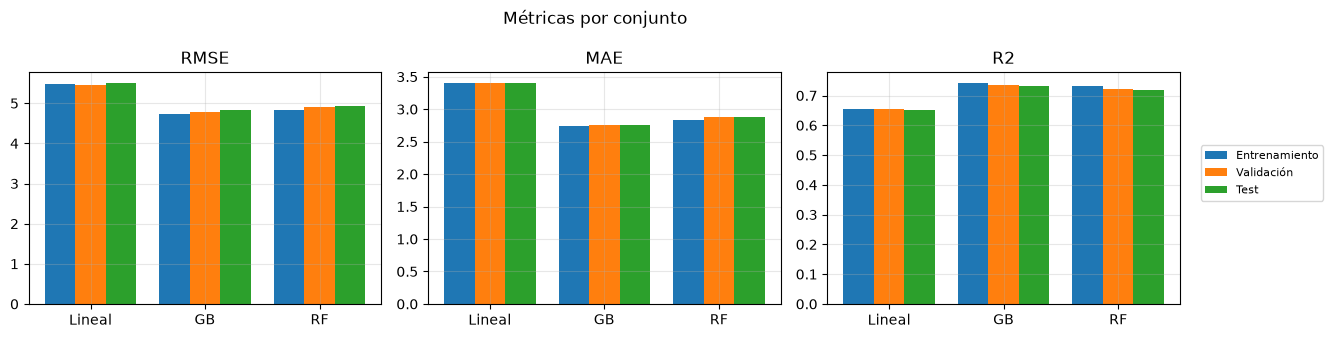

In [23]:
graficar_metricas({"Entrenamiento": train, "Validación": val, "Test": test})

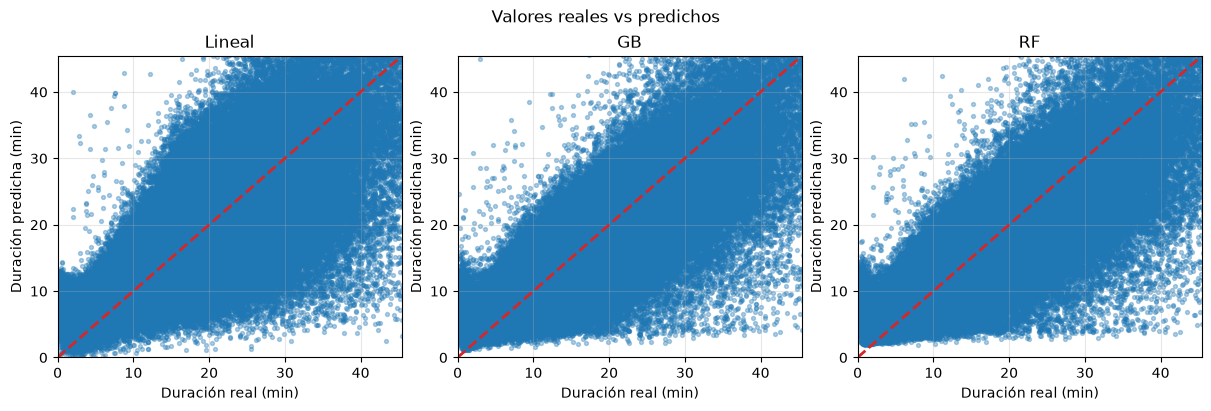

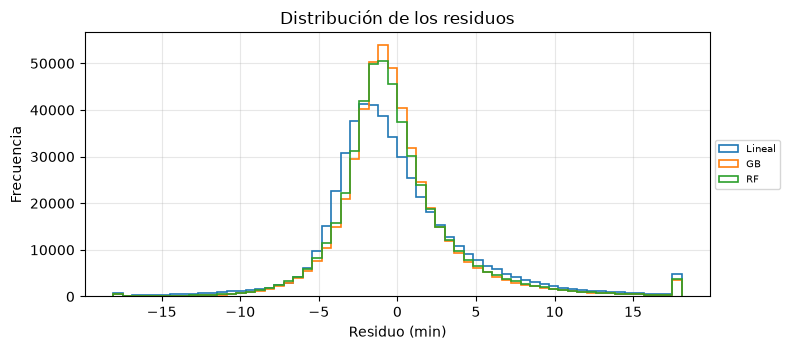

In [24]:
graficar_test(y_test, y_pred)